In [1]:
# ==============================================================================
# CELL: STACKED SPECTRA VISUALIZATION (ALL IMPACT PARAMETERS + r=0)
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# --- 0. STYLE CONFIGURATION ---
def matplotlib_default_config():
    font = {'family' : 'serif', 'weight' : 'normal', 'size' : 14}
    rcnew = {
        "mathtext.fontset" : "cm", "text.usetex": False, 'figure.frameon': True,
        'axes.linewidth': 2., "axes.titlesize" : 20, "axes.labelsize" : 20,
        "legend.fontsize" : 14, 'legend.fancybox': True, 'lines.linewidth': 2.5,
        'xtick.alignment': 'center', 'xtick.bottom': True, 'xtick.color': 'black',
        'xtick.direction': 'in', 'xtick.labelbottom': True, 'xtick.labelsize': 18,
        'xtick.major.bottom': True, 'xtick.major.pad': 6.0, 'xtick.major.size': 10.0,
        'xtick.major.width': 1.5, 'xtick.minor.bottom': True, 'xtick.minor.pad': 3.4,
        'xtick.minor.size': 5.0, 'xtick.minor.visible': True, 'xtick.minor.width': 1.0,
        'xtick.top': True, 'ytick.alignment': 'center_baseline', 'ytick.color': 'black',
        'ytick.direction': 'in', 'ytick.labelleft': True, 'ytick.labelsize': 18,
        'ytick.left': True, 'ytick.major.left': True, 'ytick.major.pad': 6.0,
        'ytick.major.size': 10.0, 'ytick.major.width': 1.5, 'ytick.minor.left': True,
        'ytick.minor.pad': 3.4, 'ytick.minor.right': True, 'ytick.minor.size': 5.0,
        'ytick.minor.visible': True, 'ytick.minor.width': 1.0, 'ytick.right': True
    }
    return font, rcnew

# Apply Config
%matplotlib widget 
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

In [2]:
# --- 1. LOAD DATA ---
file_path = '/home/vroberto/FakeSpectra_DLAs/data/fiducial_AllHalos_DLAMode_FullMap_15.pkl'
print("Carregando o DataFrame de 60 horas... Isso pode levar alguns segundos.")
df = pd.read_pickle(file_path)

# --- 2. MASS BIN FILTERING ---
# Assumindo que a massa no catálogo de grupos do MN5 está em 10^10 M_sun / h
# Se houver hubble h ~ 0.6774, você pode ajustar o fator h. 
# Aqui faremos um filtro direto assumindo as massas em 10^10 M_sun para bater com a imagem.
h = 0.6774
mass_min_code = (10**11.0) / 1e10 * h
mass_max_code = (10**11.4) / 1e10 * h

df_mass = df[(df['halo_mass'] >= mass_min_code) & (df['halo_mass'] <= mass_max_code)].copy()
n_halos_in_bin = df_mass['halo_id'].nunique()

print(f"Halos únicos no Mass Bin [10^11.0, 10^11.4]: {n_halos_in_bin}")

# Agrupar os parâmetros de impacto usando np.isclose ou arredondamento para lidar com o float32
df_mass['r_mult_round'] = df_mass['r_multiplier'].round(2)
unique_impacts = np.sort(df_mass['r_mult_round'].unique())
n_panels = len(unique_impacts)


Carregando o DataFrame de 60 horas... Isso pode levar alguns segundos.
Halos únicos no Mass Bin [10^11.0, 10^11.4]: 148


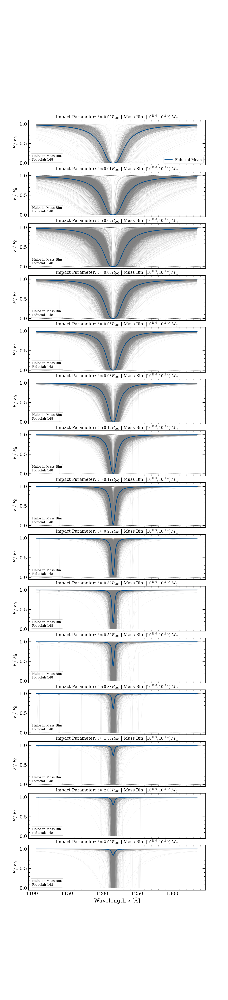

In [3]:
# --- 3. PLOTTING ---
fig, axes = plt.subplots(n_panels, 1, figsize=(12, 3.5 * n_panels), sharex=True)
if n_panels == 1: axes = [axes] # Previne erro se houver só 1 painel

lam_rest = 1215.67

for i, (ax, r_mult) in enumerate(zip(axes, unique_impacts)):
    # Isolar os dados para este painel
    df_panel = df_mass[df_mass['r_mult_round'] == r_mult]
    
    # Extrair a matriz 2D de fluxos [n_skewers, n_bins]
    # O np.vstack é extremamente eficiente para plotar milhares de linhas de uma vez
    all_fluxes = np.vstack(df_panel['flux'].values)
    
    # Garantir que usamos o array de comprimento de onda correto (da primeira linha do bloco)
    wave_axis = df_panel.iloc[0]['wave']
    
    # Calcular Estatísticas
    mean_flux = np.mean(all_fluxes, axis=0)
    std_flux = np.std(all_fluxes, axis=0)
    
    # 1. Plotar a "nuvem" de todos os skewers individuais no fundo (cinza e transparente)
    # Transpor o array all_fluxes (all_fluxes.T) plota cada coluna como uma linha separada
    ax.plot(wave_axis, all_fluxes.T, color='gray', alpha=0.15, linewidth=0.5, zorder=1)
    
    # 2. Plotar o desvio padrão (Shaded area)
    ax.fill_between(wave_axis, 
                    np.clip(mean_flux - std_flux, 0, 1), 
                    np.clip(mean_flux + std_flux, 0, 1), 
                    color='gray', alpha=0.4, zorder=2)
    
    # 3. Plotar a linha Média Principal
    ax.plot(wave_axis, mean_flux, color='#004c8c', lw=2.5, label='Fiducial Mean', zorder=3)
    
    # 4. Estilização e Linhas de Referência
    ax.axhline(1.0, color='black', linestyle=':', lw=1.5, alpha=0.6, zorder=0)
    ax.axhline(0.0, color='black', linestyle=':', lw=1.5, alpha=0.6, zorder=0)
    ax.axvline(lam_rest, color='gray', linestyle='-.', lw=1.0, alpha=0.8, zorder=0)
    
    ax.set_ylim(-0.05, 1.1)
    
    # Ajustar limites de X (Você pode afinar se quiser ver mais da asa do DLA)
    #ax.set_xlim(1205.0, 1226.0) 
    
    ax.set_ylabel(r'$F \,/\, F_0$')
    
    # Título do Painel igual à referência
    ax.set_title(rf'Impact Parameter: $b \approx {r_mult:.2f} R_{{200}}$ | Mass Bin: $[10^{{11.0}}, 10^{{11.4}}) \, M_\odot$', fontsize=16)
    
    # Caixa de Texto no canto inferior esquerdo
    textstr = f"Halos in Mass Bin:\nFiducial: {n_halos_in_bin}"
    props = dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='silver')
    ax.text(0.02, 0.08, textstr, transform=ax.transAxes, fontsize=12,
            verticalalignment='bottom', bbox=props)
    
    # Legenda apenas no primeiro painel para não poluir
    if i == 0:
        ax.legend(loc='lower right', framealpha=0.9)

# Formatação do eixo X apenas no último painel
axes[-1].set_xlabel(r'Wavelength $\lambda$ [$\mathrm{\AA}$]')

# Reduzir o espaço em branco entre os painéis
plt.subplots_adjust(hspace=0.15)
plt.show()

### Now let's show the absorption for different bins

Preparing full dataset for mass-binned colored plot...
--> Mass range detected: -0.47 to 23.49 log10(Msun)
--> Impact parameters: [0.   0.01 0.02 0.03 0.05 0.08 0.12 0.17 0.26 0.39 0.59 0.88 1.33 2.
 3.  ]

--- Halo Count per Quantile Bin ---
Bin 1 (-0.47 to 11.15): 113 unique halos
Bin 2 (11.15 to 11.46): 113 unique halos
Bin 3 (11.46 to 11.90): 113 unique halos
Bin 4 (11.90 to 23.49): 113 unique halos
-----------------------------------



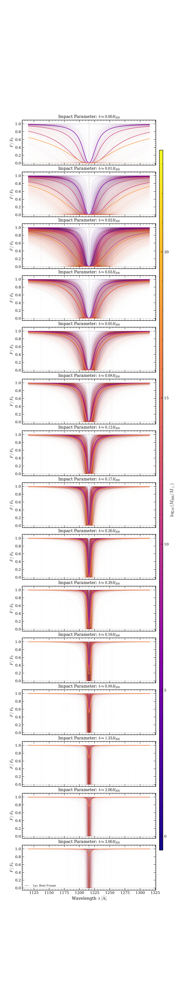

In [4]:
# ==============================================================================
# CELL 4: MASS-BINNED COLORED SPECTRA (EQUAL-COUNT BINS & FIXED CMAP)
# ==============================================================================
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np

# --- 1. DATA PREPARATION ---
print("Preparing full dataset for mass-binned colored plot...")

# Work on a copy of the full dataframe (before any single mass bin filtering)
df_all = df.copy()

# Calculate physical mass in solar masses and then log10
H_HUBBLE = 0.6774 
df_all['halo_mass_msun'] = df_all['halo_mass'] * (1e10 / H_HUBBLE)
df_all['log_mass_msun'] = np.log10(df_all['halo_mass_msun'])

# Round the impact parameters to group them correctly
df_all['r_mult_round'] = df_all['r_multiplier'].round(2)
unique_radii = np.sort(df_all['r_mult_round'].unique())

# --- DYNAMIC QUANTILE BINNING ---
NUM_BINS = 4  # 4 bins to get clear, distinct color separations

# Extract unique halos to avoid biasing the percentiles with multiple skewers per halo
unique_halos = df_all[['halo_id', 'log_mass_msun']].drop_duplicates()

# Use np.percentile to create edges that contain an equal number of halos
percentiles = np.linspace(0, 100, NUM_BINS + 1)
mass_edges = np.percentile(unique_halos['log_mass_msun'], percentiles)

# To ensure the absolute min and max are inclusive without float precision issues
mass_edges[0] -= 10
mass_edges[-1] += 10

min_mass = mass_edges[0]
max_mass = mass_edges[-1]

print(f"--> Mass range detected: {min_mass:.2f} to {max_mass:.2f} log10(Msun)")
print(f"--> Impact parameters: {unique_radii}")

# --- 2. SUMMARY PRINT ---
print("\n--- Halo Count per Quantile Bin ---")
for i in range(NUM_BINS):
    m_min = mass_edges[i]
    m_max = mass_edges[i+1]
    
    mask_global = (unique_halos['log_mass_msun'] > m_min) & (unique_halos['log_mass_msun'] <= m_max)
    num_halos = unique_halos[mask_global]['halo_id'].nunique()
    
    print(f"Bin {i+1} ({m_min:.2f} to {m_max:.2f}): {num_halos} unique halos")
print("-----------------------------------\n")

# --- 3. COLORMAP CONFIGURATION ---
# Fixed the Matplotlib deprecation warning
cmap = plt.colormaps['plasma']
norm = mcolors.Normalize(vmin=min_mass, vmax=max_mass)

# --- 4. PLOT SETUP ---
# Create figure with a row for each impact parameter
fig_colored, axes_colored = plt.subplots(
    len(unique_radii), 1, 
    figsize=(12, 4.5 * len(unique_radii)), 
    sharex=True
)
if len(unique_radii) == 1: axes_colored = [axes_colored]

# Common wavelength grid for interpolation
lam_rest = 1215.67
wave_grid = np.linspace(lam_rest - 100, lam_rest + 100, 500)

# --- 5. RENDER PANELS ---
for ax_idx, r_target in enumerate(unique_radii):
    ax = axes_colored[ax_idx]
    df_radius = df_all[df_all['r_mult_round'] == r_target]
    
    # Title
    ax.set_title(rf"Impact Parameter: $b \approx {r_target:.2f} R_{{200}}$", pad=10)

    # Iterate through each quantile mass bin
    for i in range(NUM_BINS):
        m_min = mass_edges[i]
        m_max = mass_edges[i+1]
        
        # We use the geometric/linear midpoint of the bin edges for the color mapping
        mid_mass = (m_min + m_max) / 2.0
        color = cmap(norm(mid_mass))

        # Filter dataframe for this specific bin
        df_bin = df_radius[(df_radius['log_mass_msun'] > m_min) & 
                           (df_radius['log_mass_msun'] <= m_max)]
        if df_bin.empty:
            continue

        flux_matrix = []
        
        # Plot individual lines (Raw Data)
        for _, row in df_bin.iterrows():
            w = row['wave']
            f = row['flux']
            
            # Interpolate to common grid to calculate means accurately
            f_interp = np.interp(wave_grid, w, f)
            flux_matrix.append(f_interp)
            
            # Plot with rasterized=True to prevent massive file sizes and lag
            ax.plot(wave_grid, f_interp, color=color, alpha=0.015, lw=0.5, 
                    zorder=1, rasterized=True)

        # Calculate and plot the mean line for this mass bin
        if flux_matrix:
            flux_matrix = np.array(flux_matrix)
            mean_flux = np.nanmean(flux_matrix, axis=0)
            ax.plot(wave_grid, mean_flux, color=color, lw=2.5, alpha=0.9, zorder=10)

    # Aesthetics and Reference Lines
    ax.axhline(1.0, color='black', linestyle=':', lw=1.5, alpha=0.6, zorder=0)
    ax.axhline(0.0, color='black', linestyle=':', lw=1.5, alpha=0.6, zorder=0)
    ax.axvline(lam_rest, color='gray', linestyle='-.', lw=1.0, alpha=0.8, zorder=0)

    ax.set_ylim(-0.05, 1.1)
    #ax.set_xlim(1205.0, 1226.0) 
    ax.set_ylabel(r'$F \,/\, F_0$')

# X-Axis formatting on the bottom panel
axes_colored[-1].set_xlabel(r'Wavelength $\lambda\ [\mathrm{\AA}]$')
axes_colored[-1].axvline(lam_rest, color='gray', linestyle='-.', alpha=0.8, label=r'Ly$\alpha$ Rest Frame')
axes_colored[-1].legend(loc='lower left', frameon=False, fontsize=14)

# --- 6. GLOBAL COLORBAR ---
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

# Adjust subplots to make room for the colorbar on the right
fig_colored.subplots_adjust(right=0.88, hspace=0.15) 
cbar_ax = fig_colored.add_axes([0.90, 0.15, 0.02, 0.7]) # [left, bottom, width, height]
cbar = fig_colored.colorbar(sm, cax=cbar_ax)

cbar.set_label(r'$\log_{10}(M_{200} / M_\odot)$', fontsize=22)
cbar.ax.tick_params(labelsize=18)

plt.show()